In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("C:\\Users\\Pranjali\\OneDrive\\Desktop\\RCA_2\\online_shoppers_intention.csv")

In [3]:
df.head()

,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [11]:
df.rename(columns={
    'Administrative': 'admin_pages',
    'Administrative_Duration': 'admin_time',
    'Informational': 'info_pages',
    'Informational_Duration': 'info_time',
    'ProductRelated': 'product_pages',
    'ProductRelated_Duration': 'product_time',
    'BounceRates': 'bounce_rate',
    'ExitRates': 'exit_rate',
    'PageValues': 'page_value',
    'SpecialDay': 'special_day',
    'Month': 'month',
    'OperatingSystems': 'operating_system',
    'Browser': 'browser',
    'Region': 'region',
    'TrafficType': 'traffic_type',
    'VisitorType': 'visitor_type',
    'Weekend': 'is_weekend',
    'Revenue': 'purchase'
}, inplace=True)

In [12]:
df.describe()

,admin_pages,admin_time,info_pages,info_time,product_pages,product_time,bounce_rate,exit_rate,page_value,special_day,operating_system,browser,region,traffic_type
count,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000,12330.000000
mean,2.315166,80.818611,0.503569,34.472398,31.731468,1194.746220,0.022191,0.043073,5.889258,0.061427,2.124006,2.357097,3.147364,4.069586
std,3.321784,176.779107,1.270156,140.749294,44.475503,1913.669288,0.048488,0.048597,18.568437,0.198917,0.911325,1.717277,2.401591,4.025169
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,0.000000,0.000000,0.000000,0.000000,7.000000,184.137500,0.000000,0.014286,0.000000,0.000000,2.000000,2.000000,1.000000,2.000000
50%,1.000000,7.500000,0.000000,0.000000,18.000000,598.936905,0.003112,0.025156,0.000000,0.000000,2.000000,2.000000,3.000000,2.000000
75%,4.000000,93.256250,0.000000,0.000000,38.000000,1464.157214,0.016813,0.050000,0.000000,0.000000,3.000000,2.000000,4.000000,4.000000
max,27.000000,3398.750000,24.000000,2549.375000,705.000000,63973.522230,0.200000,0.200000,361.763742,1.000000,8.000000,13.000000,9.000000,20.000000


In [13]:
df.shape

(12330, 18)

In [14]:
df.columns

Index(['admin_pages', 'admin_time', 'info_pages', 'info_time', 'product_pages',
       'product_time', 'bounce_rate', 'exit_rate', 'page_value', 'special_day',
       'month', 'operating_system', 'browser', 'region', 'traffic_type',
       'visitor_type', 'is_weekend', 'purchase'],
      dtype='object')

In [15]:
df.dtypes

admin_pages           int64
admin_time          float64
info_pages            int64
info_time           float64
product_pages         int64
product_time        float64
bounce_rate         float64
exit_rate           float64
page_value          float64
special_day         float64
month                object
operating_system      int64
browser               int64
region                int64
traffic_type          int64
visitor_type         object
is_weekend             bool
purchase               bool
dtype: object

# data quality checking

In [16]:
df.isnull().sum()

admin_pages         0
admin_time          0
info_pages          0
info_time           0
product_pages       0
product_time        0
bounce_rate         0
exit_rate           0
page_value          0
special_day         0
month               0
operating_system    0
browser             0
region              0
traffic_type        0
visitor_type        0
is_weekend          0
purchase            0
dtype: int64

In [19]:
df.duplicated().sum()

np.int64(125)

In [21]:
df.columns.is_numeric

<bound method Index.is_numeric of Index(['admin_pages', 'admin_time', 'info_pages', 'info_time', 'product_pages',
       'product_time', 'bounce_rate', 'exit_rate', 'page_value', 'special_day',
       'month', 'operating_system', 'browser', 'region', 'traffic_type',
       'visitor_type', 'is_weekend', 'purchase'],
      dtype='object')>

# EDA

In [22]:
# Numerical columns
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

# Categorical columns
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()

# Binary columns
binary_cols = ['is_weekend', 'purchase']

In [23]:
numerical_cols = [
    col for col in numerical_cols
    if col not in binary_cols
]

In [24]:
print("Numerical Columns:", numerical_cols)
print("\nCategorical Columns:", categorical_cols)
print("\nBinary Columns:", binary_cols)

Numerical Columns: ['admin_pages', 'admin_time', 'info_pages', 'info_time', 'product_pages', 'product_time', 'bounce_rate', 'exit_rate', 'page_value', 'special_day', 'operating_system', 'browser', 'region', 'traffic_type']

Categorical Columns: ['month', 'visitor_type']

Binary Columns: ['is_weekend', 'purchase']


univariate analysis

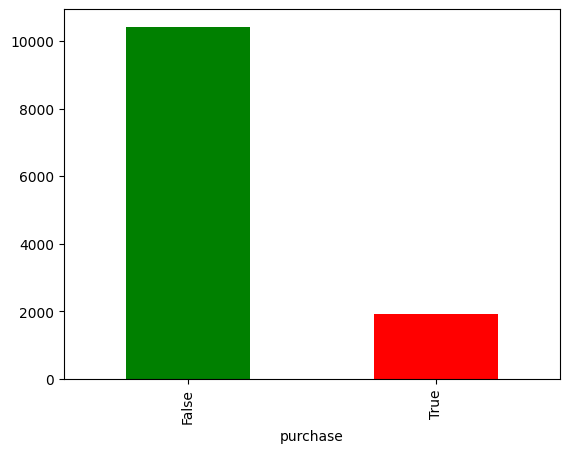

In [25]:
barchart = df['purchase'].value_counts().plot(kind='bar', color=['green', 'red'])

univariate analysis

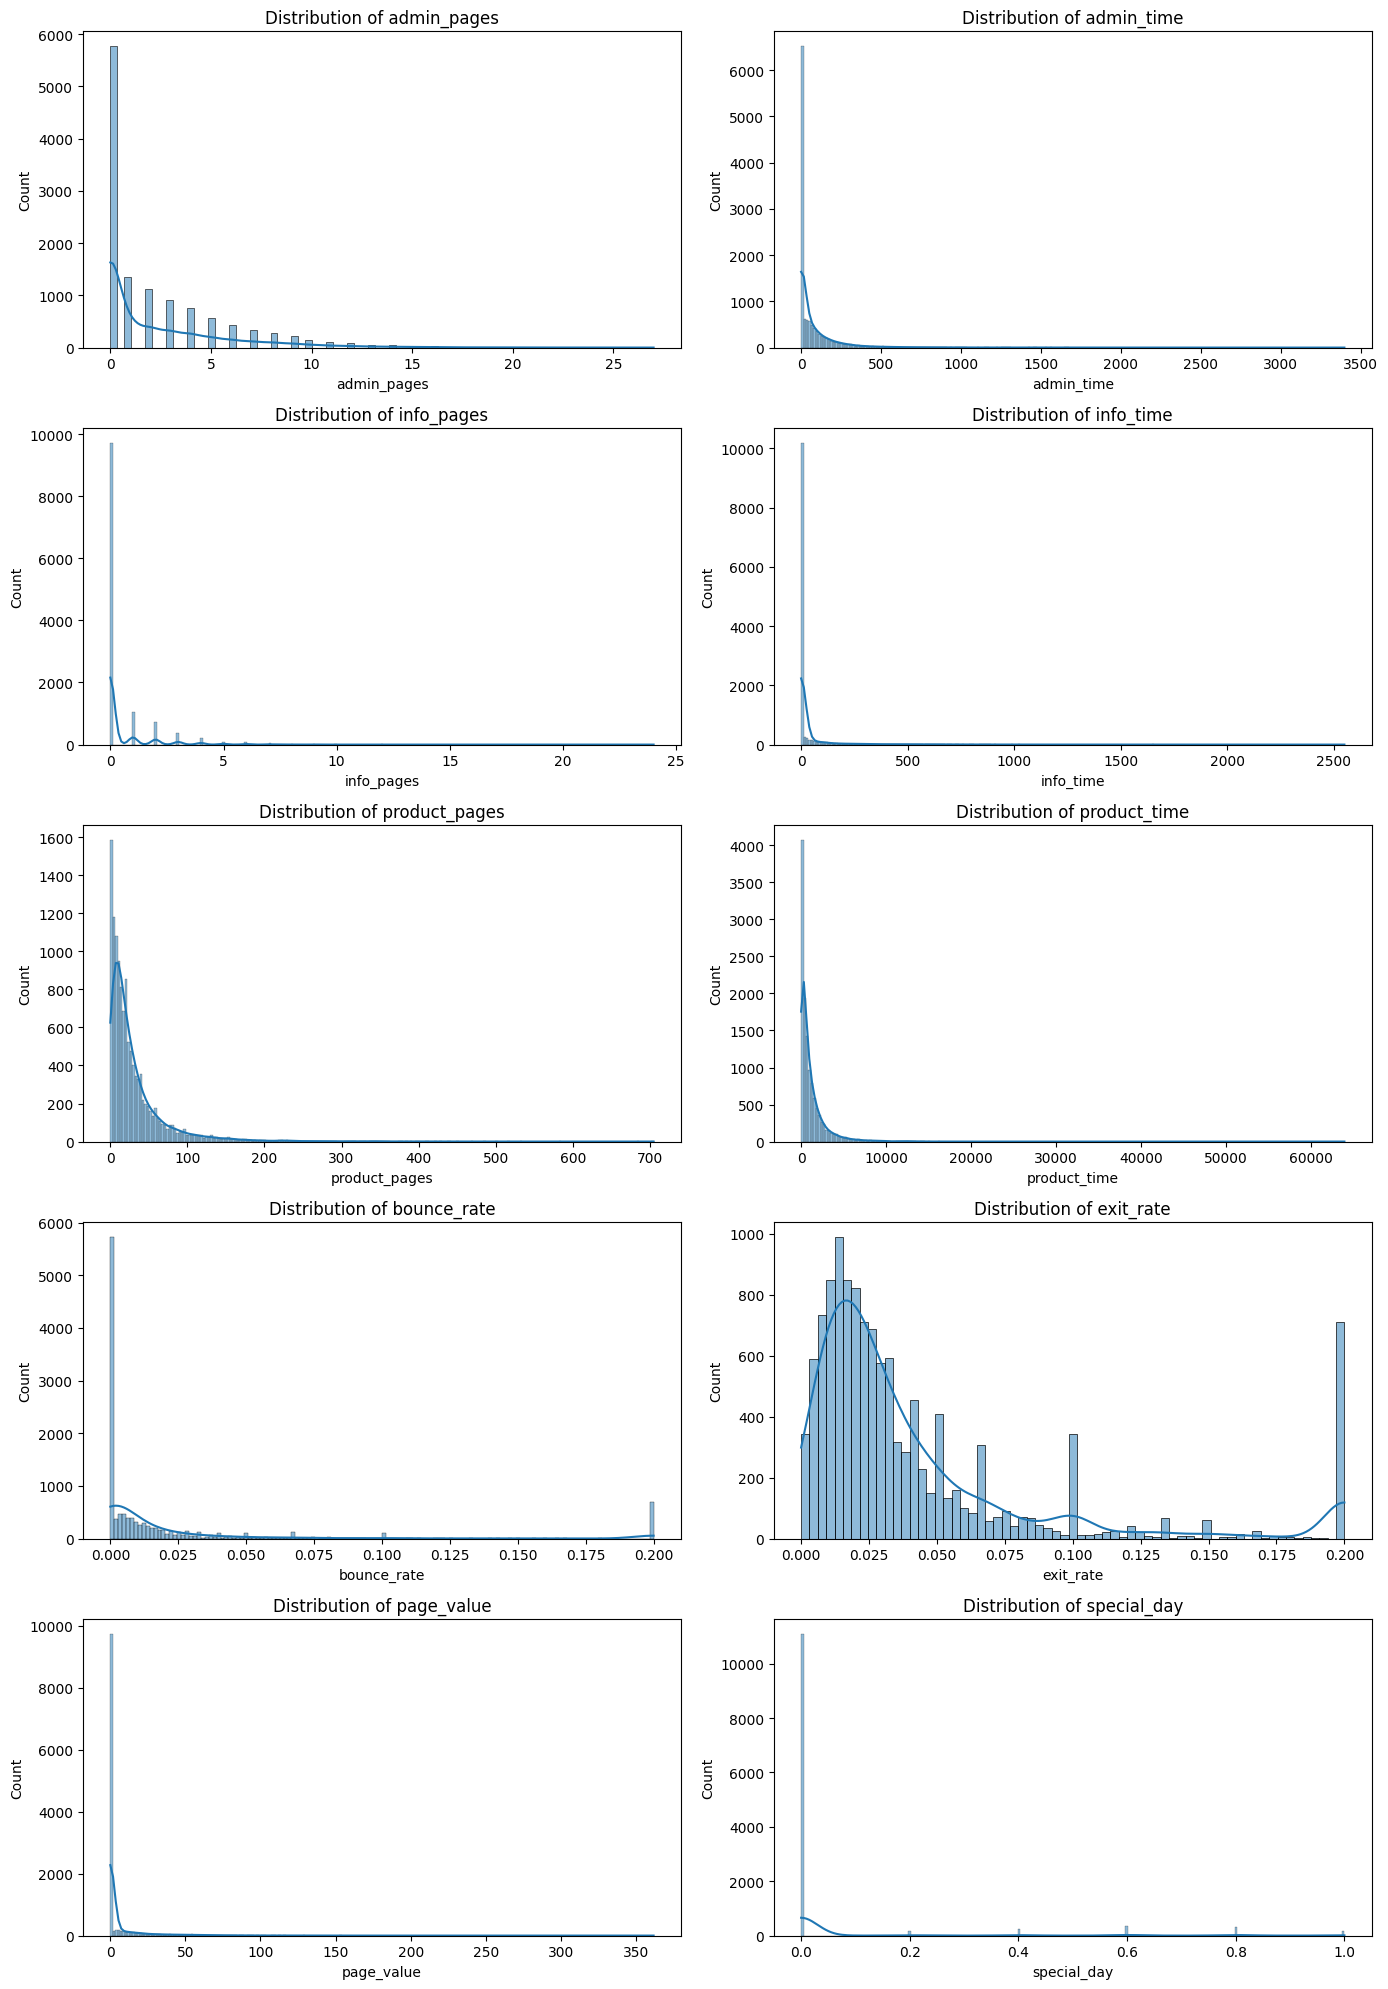

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = [
    'admin_pages', 'admin_time',
    'info_pages', 'info_time',
    'product_pages', 'product_time',
    'bounce_rate', 'exit_rate',
    'page_value', 'special_day'
]

fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for i, col in enumerate(numerical_cols):

    sns.histplot(data=df, x=col, kde=True, ax=axes[i//2, i%2])

    axes[i//2, i%2].set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

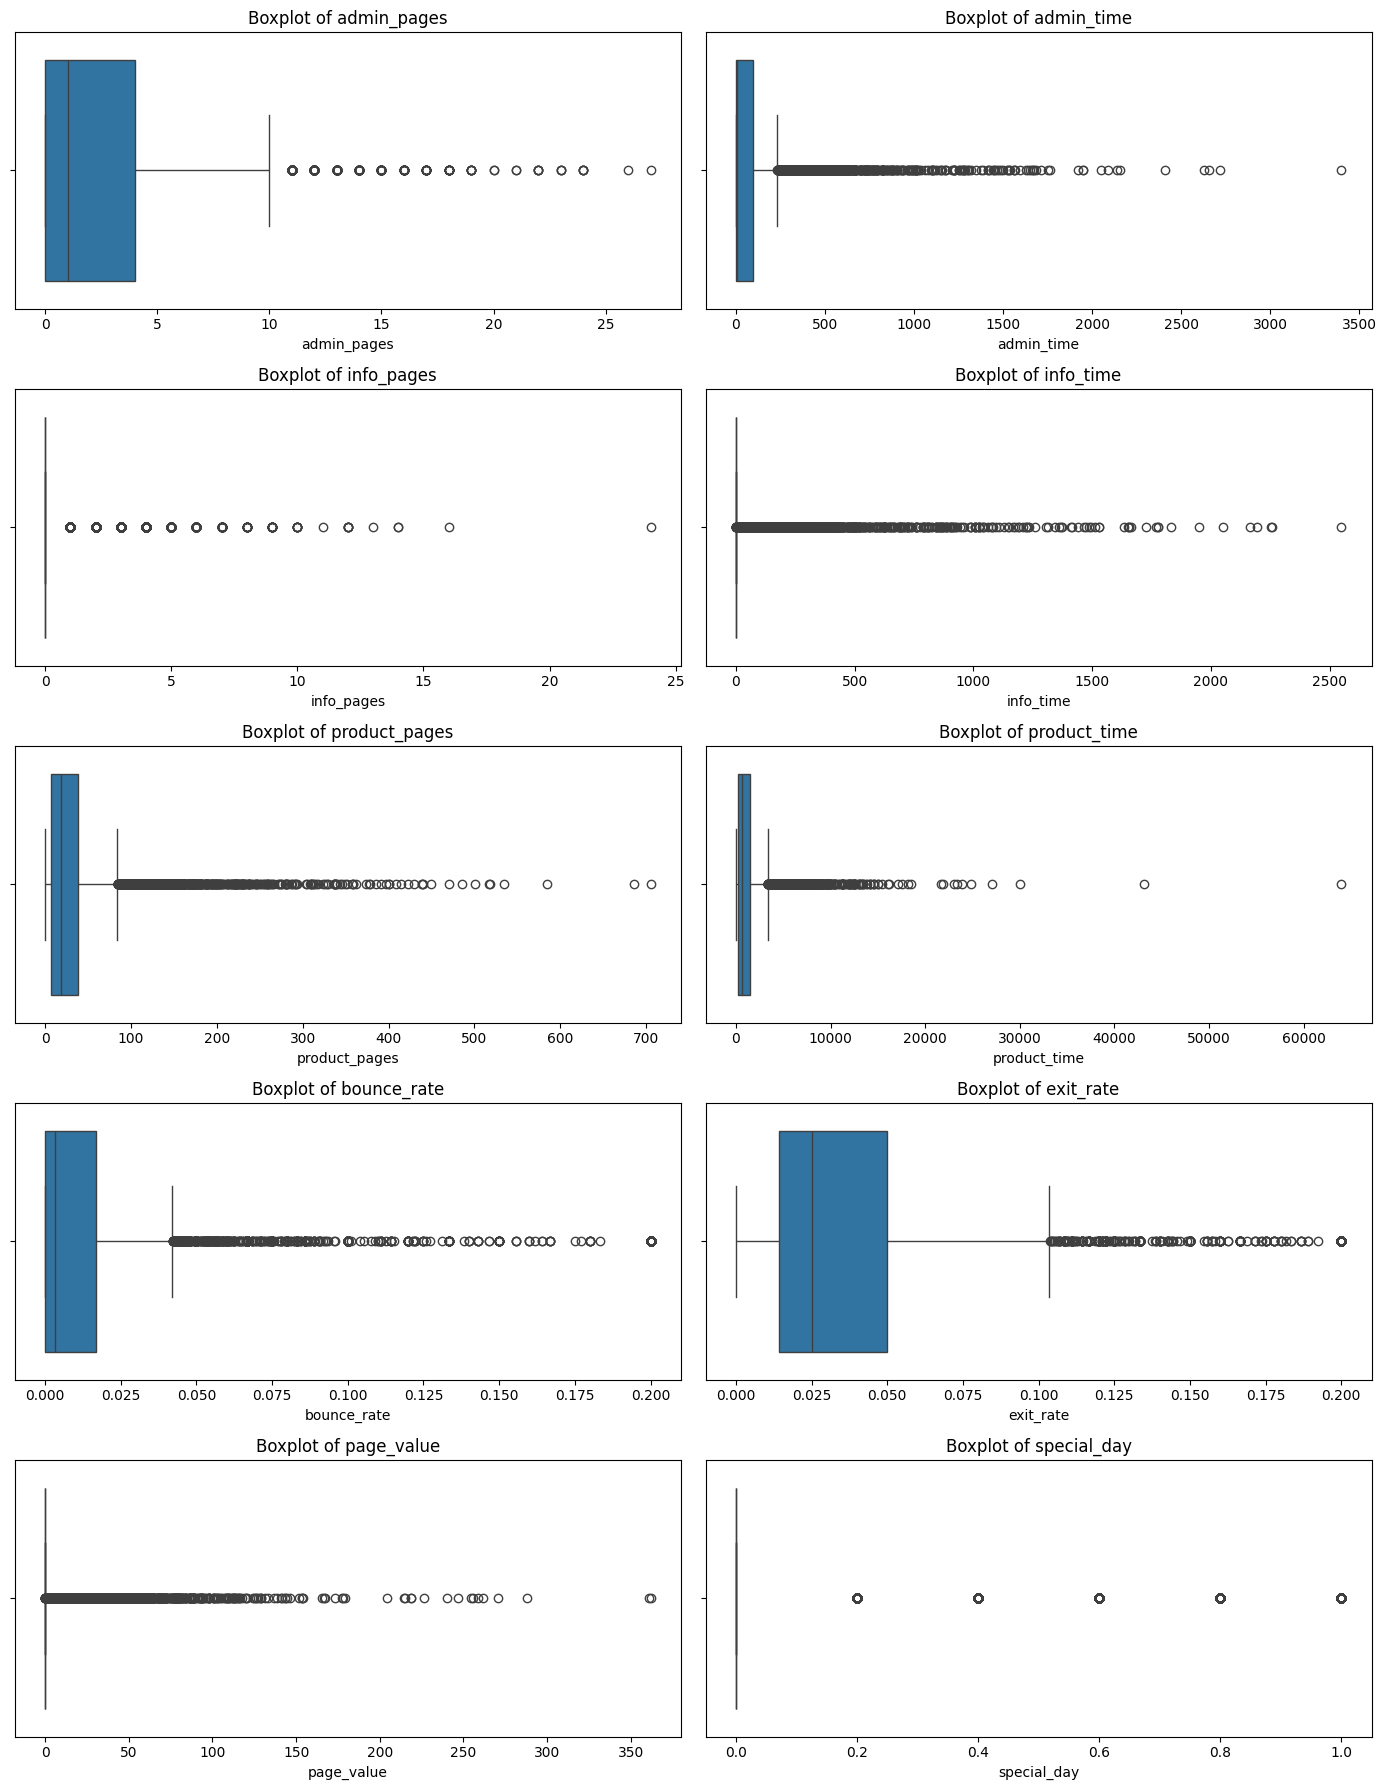

In [30]:
fig, axes = plt.subplots(5, 2, figsize=(14, 18))

for i, col in enumerate(numerical_cols):

    sns.boxplot(data=df, x=col, ax=axes[i//2, i%2])

    axes[i//2, i%2].set_title(f'Boxplot of {col}')

plt.tight_layout()
plt.show()

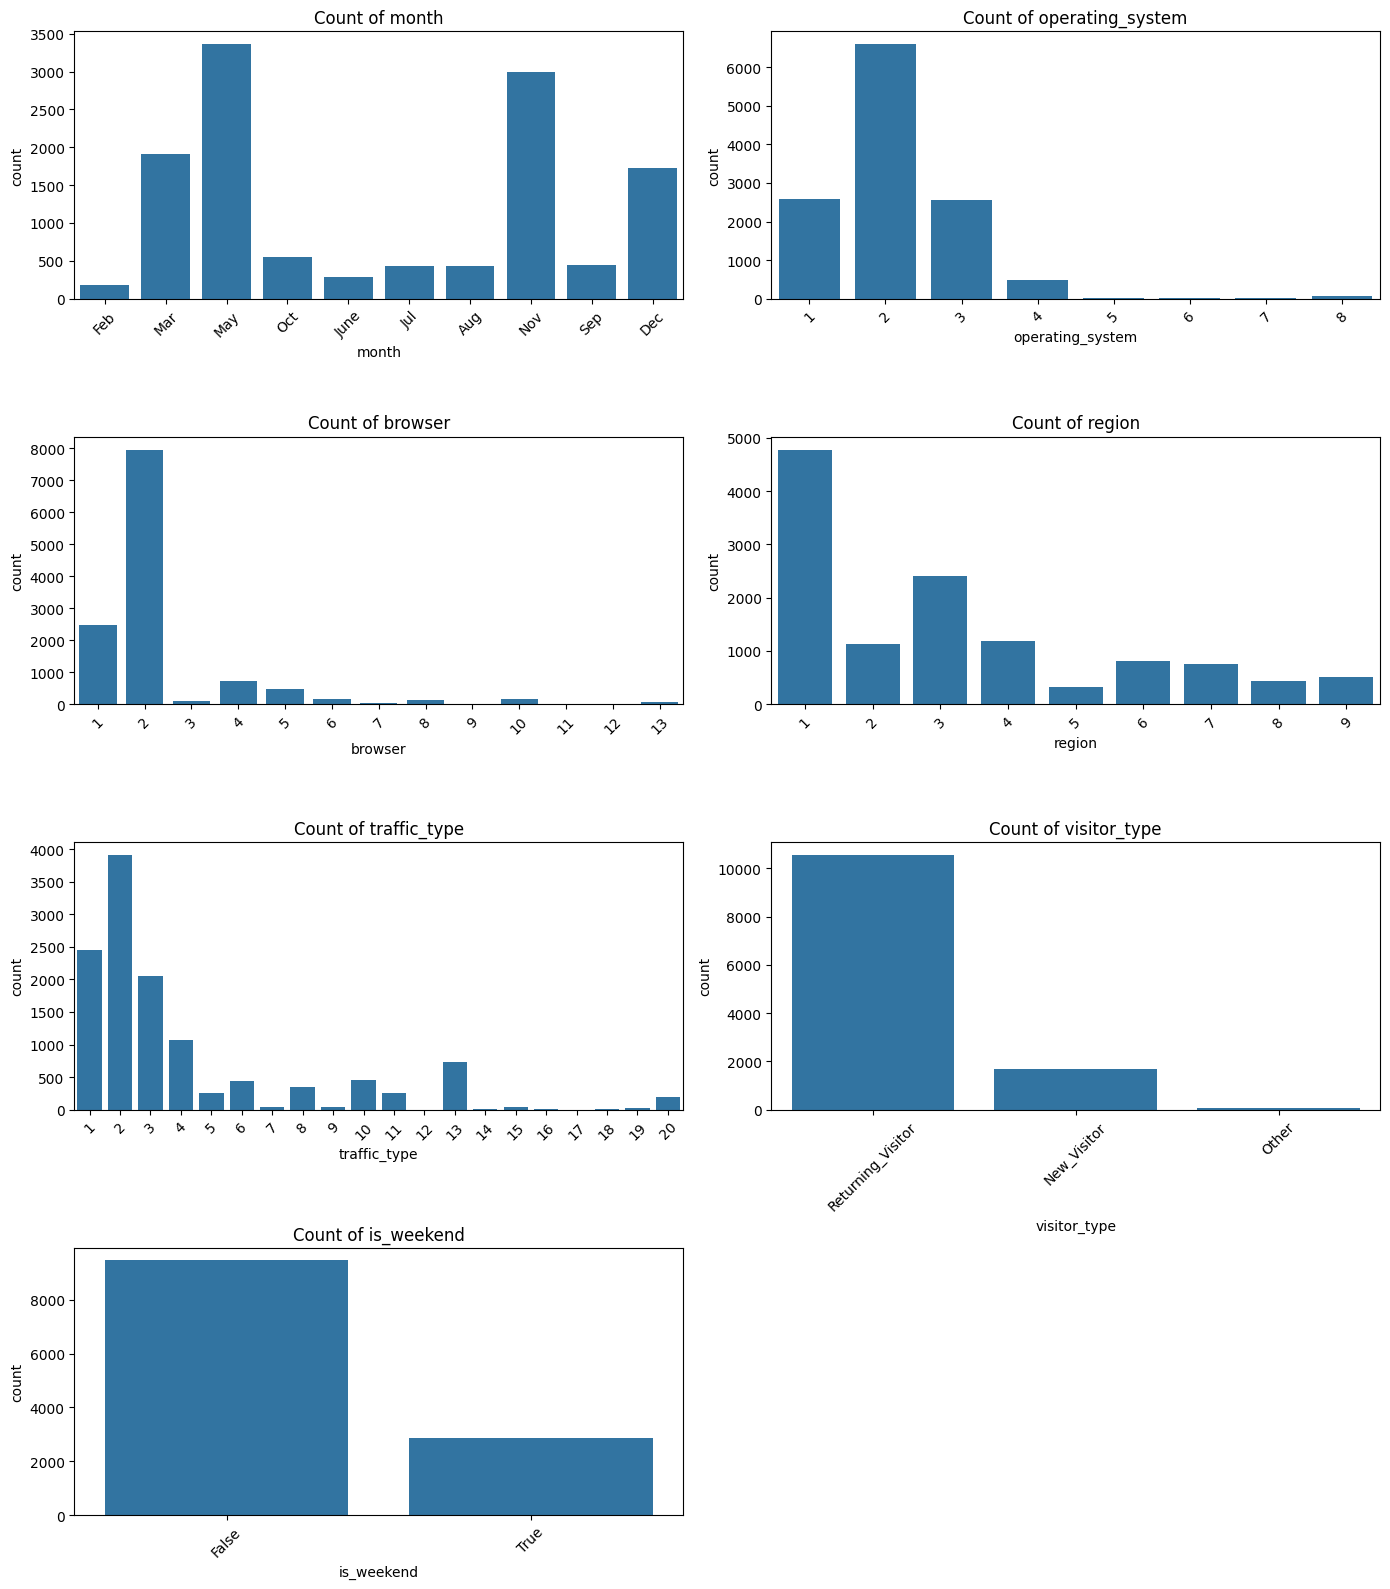

In [31]:
categorical_cols = [
    'month', 'operating_system',
    'browser', 'region',
    'traffic_type', 'visitor_type',
    'is_weekend'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for i, col in enumerate(categorical_cols):

    sns.countplot(data=df, x=col, ax=axes[i//2, i%2])

    axes[i//2, i%2].set_title(f'Count of {col}')
    axes[i//2, i%2].tick_params(axis='x', rotation=45)

axes[3, 1].set_visible(False)

plt.tight_layout()
plt.show()

Univariate analysis was performed to understand individual feature distributions using histograms, boxplots and count plots. Most numerical features showed right-skewed distributions, with some potential outliers and zero-concentrated values. Categorical features were examined to understand their frequency distributions. These observations helped identify unusual patterns and understand the characteristics of the dataset.

bivariate analsysis

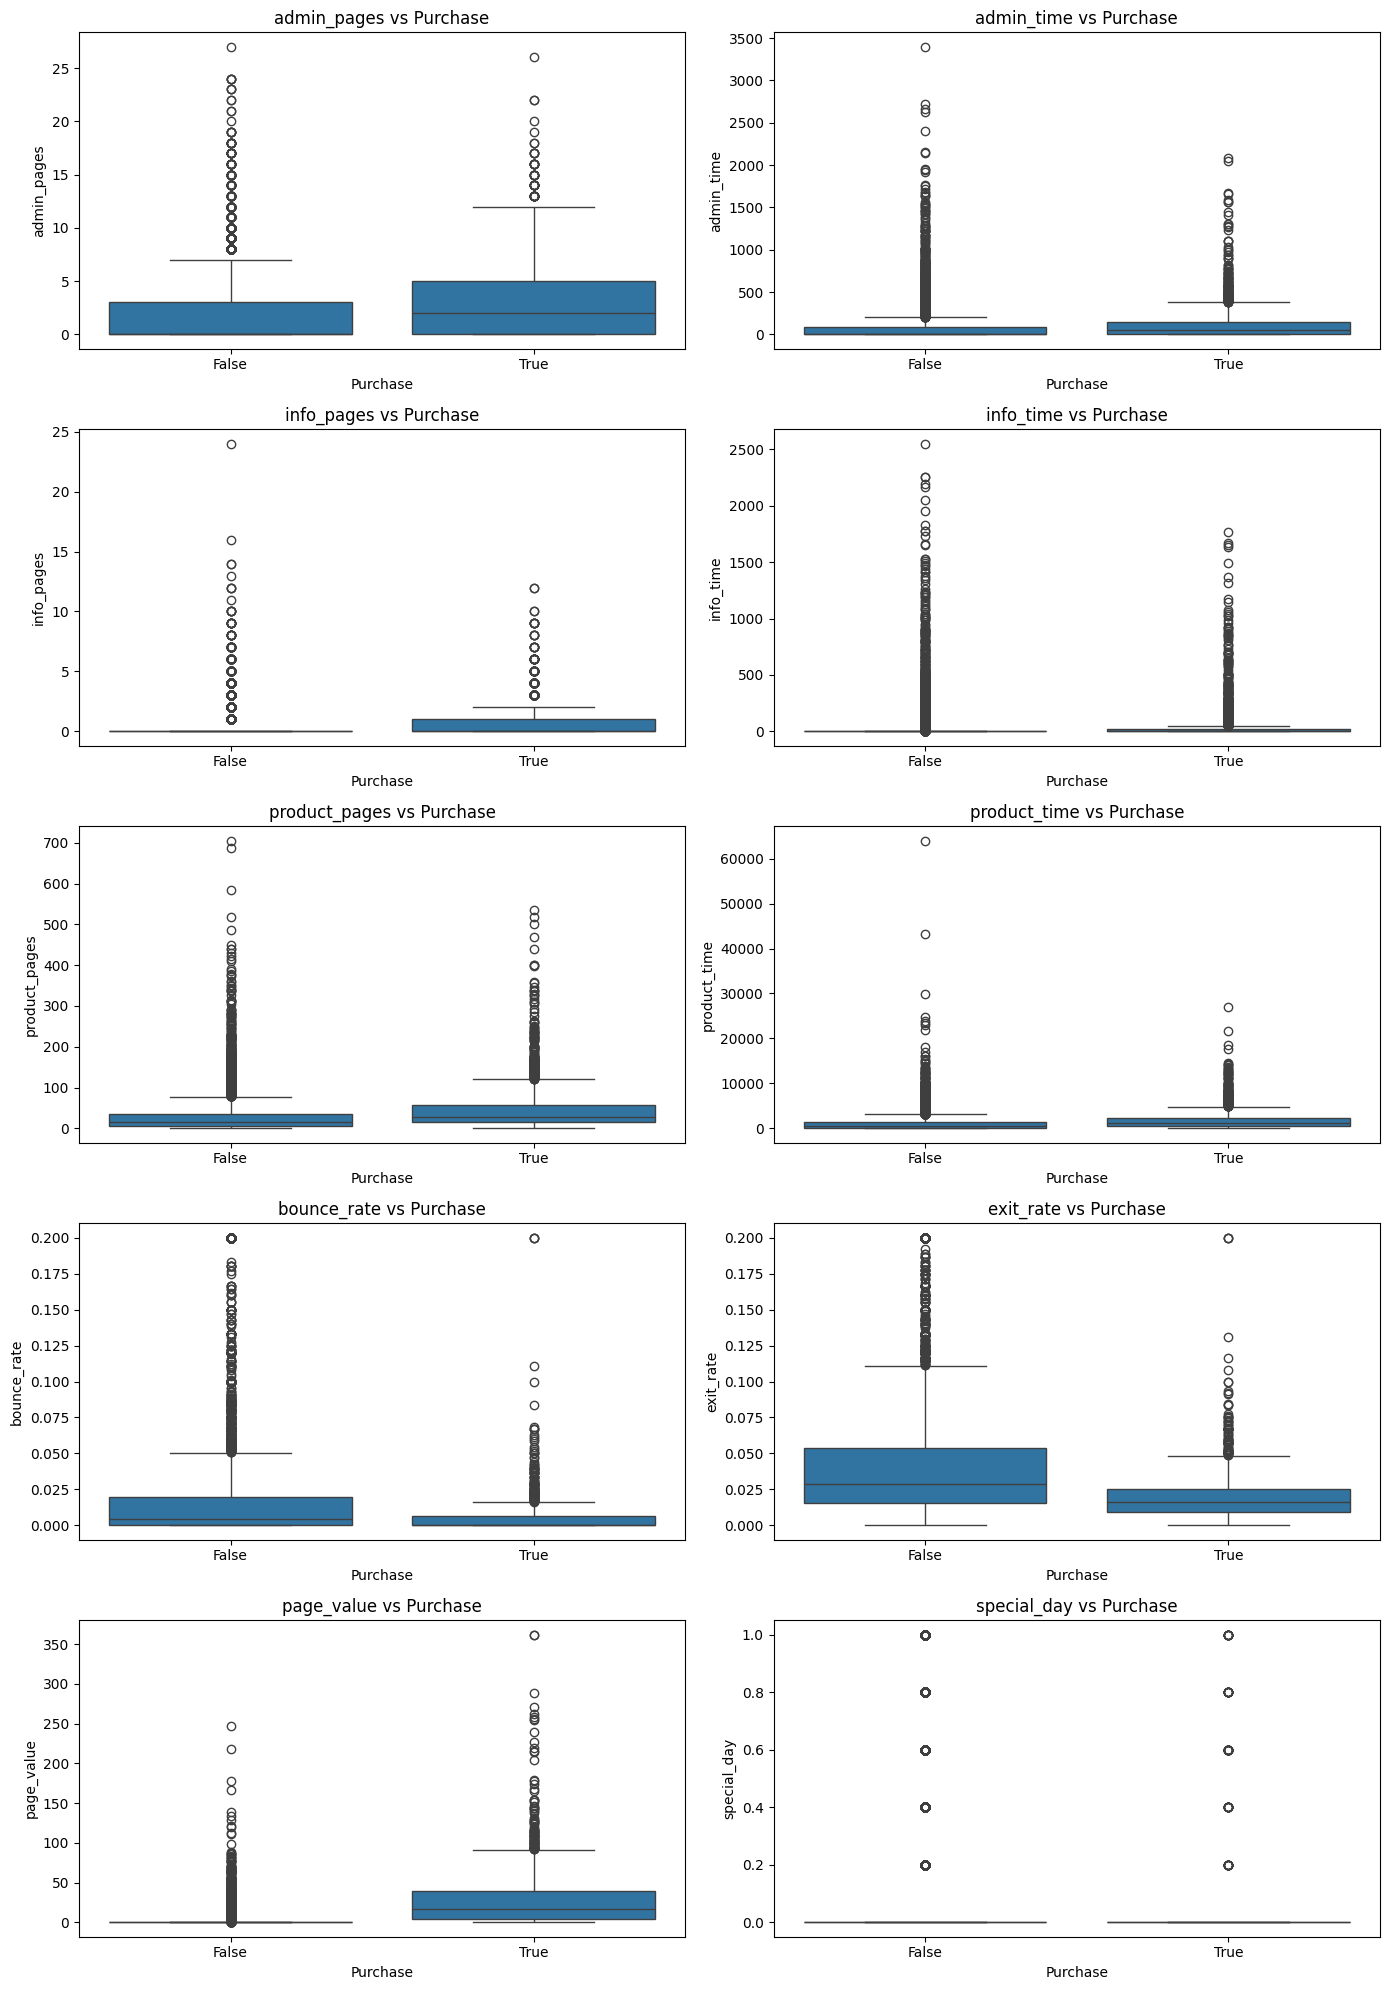

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_cols = [
    'admin_pages', 'admin_time',
    'info_pages', 'info_time',
    'product_pages', 'product_time',
    'bounce_rate', 'exit_rate',
    'page_value', 'special_day'
]

fig, axes = plt.subplots(5, 2, figsize=(14, 20))

for i, col in enumerate(numerical_cols):

    sns.boxplot(data=df, x='purchase', y=col, ax=axes[i//2, i%2])

    axes[i//2, i%2].set_title(f'{col} vs Purchase')
    axes[i//2, i%2].set_xlabel('Purchase')
    axes[i//2, i%2].set_ylabel(col)

plt.tight_layout()
plt.show()

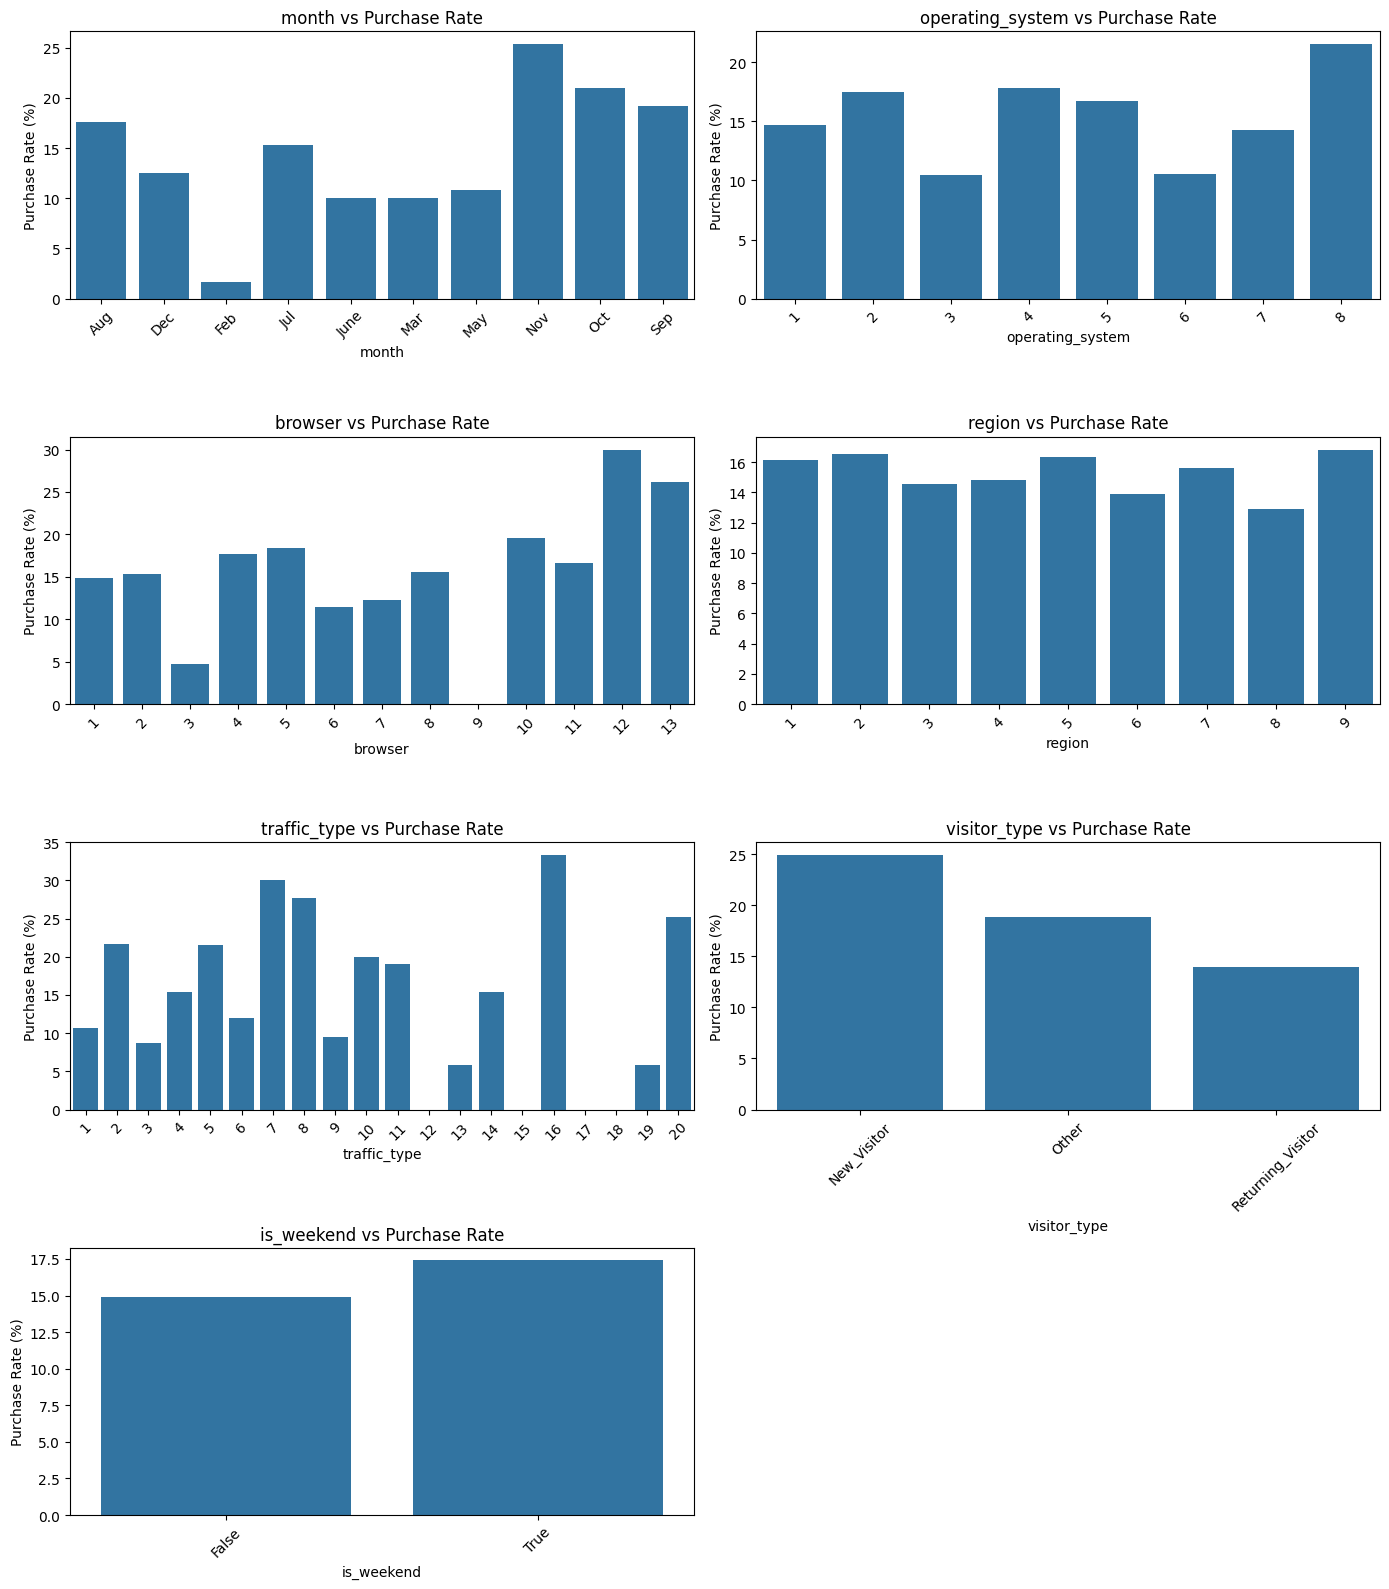

In [28]:
categorical_cols = [
    'month', 'operating_system',
    'browser', 'region',
    'traffic_type', 'visitor_type',
    'is_weekend'
]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))

for i, col in enumerate(categorical_cols):

    purchase_rate = df.groupby(col)['purchase'].mean() * 100

    sns.barplot(
        x=purchase_rate.index,
        y=purchase_rate.values,
        ax=axes[i//2, i%2]
    )

    axes[i//2, i%2].set_title(f'{col} vs Purchase Rate')
    axes[i//2, i%2].set_xlabel(col)
    axes[i//2, i%2].set_ylabel('Purchase Rate (%)')
    axes[i//2, i%2].tick_params(axis='x', rotation=45)

# Hide the unused subplot
axes[3, 1].set_visible(False)

plt.tight_layout()
plt.show()

Bivariate analysis was performed to examine the relationship between individual features and the target variable, purchase. Boxplots were used to compare numerical features across purchase classes, while bar plots were used to compare category-wise purchase rates. This analysis helped identify potential differences in visitor behaviour between purchasing and non-purchasing sessions.

multivariate analysis

In [32]:
numerical_cols = [
    'admin_pages', 'admin_time',
    'info_pages', 'info_time',
    'product_pages', 'product_time',
    'bounce_rate', 'exit_rate',
    'page_value', 'special_day'
]

# Include purchase after converting True/False to 1/0
heatmap_cols = numerical_cols + ['purchase']

correlation = df[heatmap_cols].corr()

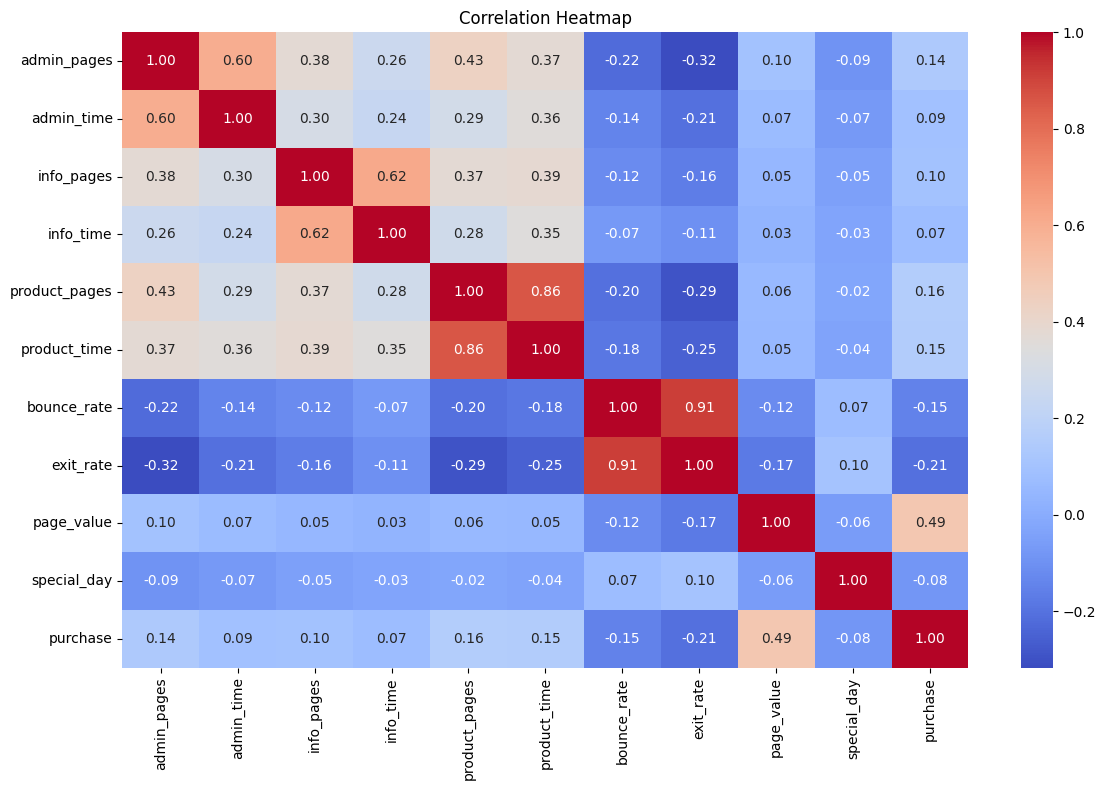

In [33]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

Multivariate analysis was performed using a correlation heatmap to examine relationships among numerical features and the target variable. Strong positive correlations were observed between bounce_rate and exit_rate (0.91), and between product_pages and product_time (0.86). This helped identify potentially redundant features and understand linear associations with the target

In [34]:
# Correlation of all features with purchase

target_corr = correlation['purchase'].drop('purchase')

# Sort correlations by absolute strength
target_corr = target_corr.reindex(
    target_corr.abs().sort_values(ascending=False).index
)

print(target_corr)

page_value       0.492569
exit_rate       -0.207071
product_pages    0.158538
product_time     0.152373
bounce_rate     -0.150673
admin_pages      0.138917
info_pages       0.095200
admin_time       0.093587
special_day     -0.082305
info_time        0.070345
Name: purchase, dtype: float64


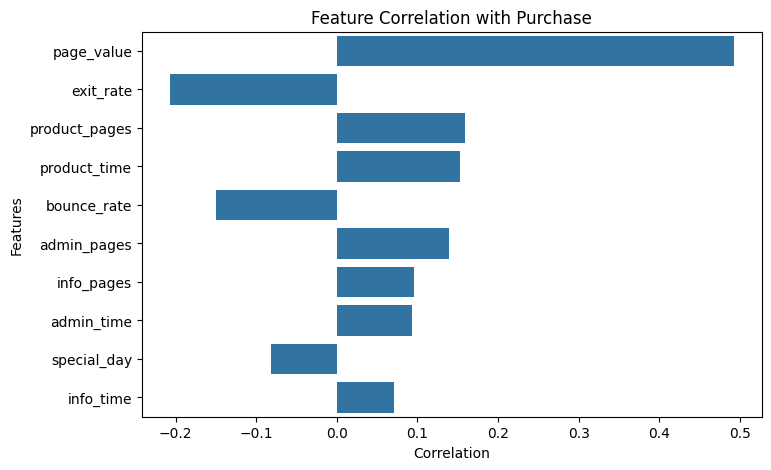

In [35]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=target_corr.values,
    y=target_corr.index
)

plt.title('Feature Correlation with Purchase')
plt.xlabel('Correlation')
plt.ylabel('Features')

plt.show()

After completing univariate, bivariate and multivariate analysis, features will be evaluated based on their relationship with the target variable, data distribution, potential outliers, redundancy, domain relevance and prediction-time availability. Correlation analysis will be used as an initial screening technique to identify linear relationships among numerical variables. Final feature selection will be based on these combined findings and validated through model performance. Features will not be removed solely because of skewness, outliers or weak correlation.

# model  building

In [37]:
# train test split
x = df.drop('purchase', axis=1)
y = df['purchase']

In [38]:
x = x.drop('page_value', axis=1)

In [39]:
numerical_cols = [
    'admin_pages', 'admin_time',
    'info_pages', 'info_time',
    'product_pages', 'product_time',
    'bounce_rate', 'exit_rate',
    'special_day'
]

categorical_cols = [
    'month', 'operating_system',
    'browser', 'region',
    'traffic_type', 'visitor_type',
    'is_weekend'
]

In [48]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42,
    stratify=y # its used becuase our target variable is imbalnced
)

In [41]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ]
)

In [42]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

model = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])

In [43]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transform

In [57]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1] ## Get the predicted probabilities of purchase (class 1) for the test data
y_pred = (y_prob >= 0.2).astype(int)

In [56]:
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
print("Accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.7064071370640713
[[1515  569]
 [ 155  227]]
              precision    recall  f1-score   support

       False       0.91      0.73      0.81      2084
        True       0.29      0.59      0.39       382

    accuracy                           0.71      2466
   macro avg       0.60      0.66      0.60      2466
weighted avg       0.81      0.71      0.74      2466



In [54]:
from sklearn.metrics import confusion_matrix, classification_report

for threshold in [ 0.4,0.5]:

    y_pred_new = (y_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print(confusion_matrix(y_test, y_pred_new))
    print(classification_report(y_test, y_pred_new))


Threshold: 0.4
[[2016   68]
 [ 334   48]]
              precision    recall  f1-score   support

       False       0.86      0.97      0.91      2084
        True       0.41      0.13      0.19       382

    accuracy                           0.84      2466
   macro avg       0.64      0.55      0.55      2466
weighted avg       0.79      0.84      0.80      2466


Threshold: 0.5
[[2070   14]
 [ 369   13]]
              precision    recall  f1-score   support

       False       0.85      0.99      0.92      2084
        True       0.48      0.03      0.06       382

    accuracy                           0.84      2466
   macro avg       0.67      0.51      0.49      2466
weighted avg       0.79      0.84      0.78      2466



Different thresholds were tested to improve purchase prediction. A threshold of 0.2 gave the highest F1-score (0.39), providing a better balance between precision and recall. Therefore, 0.2 is our provisional best threshold, which will be confirmed using validation data.v